<img src="https://github.com/juanatga/DSB-Unit-03/blob/main/labs/01%20-%20Regression-Sacramento/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Lab: Simple Linear Regression with Sacramento Real Estate Data

---

In this lab you will hone your exploratory data analysis (EDA) skills and practice constructing linear regressions on a data set of Sacramento real estate sales.  The data set contains information on qualities of the property, location of the property, and time of sale.

# Author: JUAN OROZCOVICH

### 1. Read in the Sacramento housing data set.

The file is stored in the `data` subfolder.

In [1]:
# STEP ZERO: IMPORT THE LIBRARIES YOU NEED
# FOR NOW, IMPORT ALL THE LIBRARIES YOU MIGHT NEED
# IT DOESN'T HURT TO IMPORT MORE THAN YOU NEED,
# BUT IT'S GOOD PRACTICE TO ONLY IMPORT WHAT YOU USE

import pandas as pd          # Data manipulation
import numpy as np           # Numerical operations
import matplotlib.pyplot as plt
import seaborn as sns        # Beautiful plots (builds on matplotlib)
from scipy import stats      # Correlation and statistical functions

# THE LAST IMPORT IS DIFFERENT THAN THE OTHERS: IT ONLY IMPORTS A FUNCTION FROM
# THAST LIBRARY, NOT THE ENTIRE LIBRARY. THIS IS FASTER

In [2]:
# STEP 1: LOAD DATA

# I PREFER TO USE A VARIABLE (IN THE CASE RAW_PATH) BECAUSE THAT WAY IS EASIER
# AND SAFER TO CHANGE THE PATH LATER IF YOU NEED TO. THIS IS USEFUL IF YOU ARE
# ON VS CODE (to read the file from a local path) AND
# IN GOOGLE COLAB OR ANY OTHER PLATFORM (to read from a url).

raw_path = 'https://raw.githubusercontent.com/CharleyHananiaGA/DSB-Unit-03/refs/heads/main/labs/01%20-%20Regression-Sacramento/data/sacramento_real_estate_transactions.csv'
raw_df = pd.read_csv(raw_path)

In [3]:
# AFTER READING THE DATA, IT'S GOOD PRACTICE TO CHECK THE FIRST FEW ROWS TO MAKE
# SURE IT LOADED CORRECTLY. FIRST FIVE ROWS IS ENOUGH.
display(raw_df.head(5))

# WHEN YOU WANT TO SEE ONLY ONE THING, DISPLAY IS NICER THAN PRINT, BUT IT'S NOT NECESSARY. YOU
# CAN USE PRINT INSTEAD IF YOU WANT.

# I ALSO LIKE TO CHECK THE SHAPE OF THE DATAFRAME (NUMBER OF ROWS AND COLUMNS) TO
# MAKE SURE IT'S WHAT I EXPECTED. THIS IS ESPECIALLY USEFUL
# WHEN YOU ARE READING DATA FROM A URL, BECAUSE SOMETIMES THE URL
# MIGHT NOT BE AVAILABLE OR MIGHT HAVE CHANGED, AND YOU END UP WITH AN
# EMPTY DATAFRAME. CHECKING THE SHAPE IS A QUICK WAY TO CATCH THAT.
display(raw_df.shape)

# AFTER THAT I LIKE A QUICK INFO TO CHECK DATA TYPES AND NULL COUNTS
display(raw_df.info())

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
0,3526 HIGH ST,SACRAMENTO,95838,CA,2,1,836,Residential,Wed May 21 00:00:00 EDT 2008,59222,38.631913,-121.434879
1,51 OMAHA CT,SACRAMENTO,95823,CA,3,1,1167,Residential,Wed May 21 00:00:00 EDT 2008,68212,38.478902,-121.431028
2,2796 BRANCH ST,SACRAMENTO,95815,CA,2,1,796,Residential,Wed May 21 00:00:00 EDT 2008,68880,38.618305,-121.443839
3,2805 JANETTE WAY,SACRAMENTO,95815,CA,2,1,852,Residential,Wed May 21 00:00:00 EDT 2008,69307,38.616835,-121.439146
4,6001 MCMAHON DR,SACRAMENTO,95824,CA,2,1,797,Residential,Wed May 21 00:00:00 EDT 2008,81900,38.519470,-121.435768


(985, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 985 entries, 0 to 984
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   street     985 non-null    object 
 1   city       985 non-null    object 
 2   zip        985 non-null    int64  
 3   state      985 non-null    object 
 4   beds       985 non-null    int64  
 5   baths      985 non-null    int64  
 6   sq__ft     985 non-null    int64  
 7   type       985 non-null    object 
 8   sale_date  985 non-null    object 
 9   price      985 non-null    int64  
 10  latitude   985 non-null    float64
 11  longitude  985 non-null    float64
dtypes: float64(2), int64(5), object(5)
memory usage: 92.5+ KB


None

In [4]:
raw_df.zip.value_counts(sort=True, ascending=False, dropna=False)

,count
zip,
95648,72
95823,61
95828,45
95758,44
95838,37
...,...
95663,1
95619,1
95614,1


### 2. Conduct exploratory data analysis on this data set.

If you discover any issues with the data, fix them to the best of your ability. Report any notable findings.

_**Note:** Zip codes often have leading zeros — e.g., 02215 = Boston, MA — which will often get knocked off automatically by many software programs like Python or Excel._

In [5]:
# NEVER IGNORE A NOTE THAT COMES WITH YOUR DATA OR YOUR QATA SCIENCE PROBLEM
# IN THIS CASE, ZIP CODES ARE NOT REALLY NUMERIC, SO WE SHOULD TREAT THEM AS
# CATEGORICAL VARIABLES

# WHY DOES THIS MATTER NOW?
# BECAUSE IT AFFECTS THE DATA INGESTION AND THIS IS A
# COMMON ISSUE IN DATA SCIENCE AND DATA ANALYTICS. IF YOU DON'T CATCH IT EARLY,
# IT CAN CAUSE PROBLEMS LATER ON.

# EASY CHECK: IF THAT COLUMN WAS IMPORTED AS AN INTEGER, THE ZEROES AT THE
# BEGINNING OF THE ZIP CODES WOULD BE LOST.

print("\nZip code dtype:", raw_df['zip'].dtype)


Zip code dtype: int64


In [6]:
# ZIP WAS IMPORTED AS AN INTEGER, SO WE NEED TO DO SEVERAL THINGS:
# 1- CONVERT IT TO A STRING ) WE DO THAT WITH .astype(str) AND
# 2- ADD THE ZEROES AT THE BEGINNING TO EVERY ZIP CODE HAS 5 DIGITS. WE DO THAT WITH .str.zfill(5).

#Zip  355 (int) - 00355

# How do you fix thi
# 355 -> "355"
# "355" -> "00355"

raw_df['zip'] = raw_df['zip'].astype(str).str.zfill(5)


# IF ZOU READ THE ENTIRE NOTEBOOK BEFORE IMPORTING THE CSV FILE, ZOU CAN ALSO
# FIX THAT IN THE read_csv FUNCTION BY ADDING THE PARAMETER dtype={'zip': str}.
# THIS WAY, PANDAS WILL READ THE ZIP CODES AS STRINGS FROM THE BEGINNING, AND
# YOU WON'T HAVE TO CONVERT THEM LATER.

# -------------------------------
# WITH THIS, WE HAVE FINISHED THE DATA INGESTION AND INITIAL CHECKS. NOW WE CAN MOVE ON TO
# THE NEXT STEP, WHICH IS UNDERSTANDING THE DATA, IDENTIFYING ISSUES, CLEANING AND CHANGING WHAT WE
# NEED TO CHANGE ---> EXPLORATORY DATA ANALYSIS (EDA)
# -------------------------------

In [7]:
text_df = raw_df.select_dtypes(exclude='number')
text_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 985 entries, 0 to 984
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   street     985 non-null    object
 1   city       985 non-null    object
 2   zip        985 non-null    object
 3   state      985 non-null    object
 4   type       985 non-null    object
 5   sale_date  985 non-null    object
dtypes: object(6)
memory usage: 46.3+ KB


In [8]:
# I do this instead of a describe() as there is no easy describe for text
for col in text_df.columns:
    display(text_df[col].value_counts())

,count
street,
8306 CURLEW CT,2
4734 14TH AVE,2
1223 LAMBERTON CIR,2
7 CRYSTALWOOD CIR,2
8369 FOPPIANO WAY,1
...,...
8616 ROCKPORTE CT,1
4128 HILL ST,1
1409 47TH ST,1


,count
city,
SACRAMENTO,439
ELK GROVE,114
LINCOLN,72
ROSEVILLE,48
CITRUS HEIGHTS,35
ANTELOPE,33
RANCHO CORDOVA,28
EL DORADO HILLS,23
NORTH HIGHLANDS,21


,count
zip,
95648,72
95823,61
95828,45
95758,44
95838,37
...,...
95663,1
95619,1
95614,1


,count
state,
CA,984
AC,1


,count
type,
Residential,917
Condo,54
Multi-Family,13
Unkown,1


,count
sale_date,
Mon May 19 00:00:00 EDT 2008,268
Fri May 16 00:00:00 EDT 2008,264
Tue May 20 00:00:00 EDT 2008,177
Wed May 21 00:00:00 EDT 2008,158
Thu May 15 00:00:00 EDT 2008,118


In [9]:
# FIRST, LETS LOOK AND THE NUMERICAL COLUMNS AND THEIR DISTRIBUTIONS. THIS IS A
# GOOD WAY TO START UNDERSTANDING THE DATA.

display(raw_df.describe().T.round(2))

# WHAT AM I LOKING FOR HERE? ARE THE MIN AND MAX VALUES AS EXPECTED? DO THEY
# MAKE SENSE OR NOT?

,count,mean,std,min,25%,50%,75%,max
beds,985.0,2.91,1.31,0.00,2.00,3.00,4.00,8.00
baths,985.0,1.78,0.90,0.00,1.00,2.00,2.00,5.00
sq__ft,985.0,1312.92,856.12,-984.00,950.00,1304.00,1718.00,5822.00
price,985.0,233715.95,139088.82,-210944.00,145000.00,213750.00,300000.00,884790.00
latitude,985.0,38.45,5.10,-121.50,38.48,38.63,38.70,39.02
longitude,985.0,-121.19,5.10,-121.55,-121.45,-121.38,-121.29,38.67


In [10]:
# BEDS AND BATHS HAVE A MINIMUM VALUE OF 0, IS THAT POSSIBLE OR IS IT A MISTAKE?
# THE PRICE AND SQUARE FEET HAVE A NEGATIVE MINIMUM, THAT MAKES NO SENSE. CAN
# THEY BE ZERO?

# I WANT TO KNOW HOW MANY ROWS HAVE THOSE VALUES AND WHAT ELSE IS IN THOSE ROWS.
# HOW DO I DO THAT? ---> FILTERING

# FIRST I CREATE A FILTER THAT WILL RETURN TRUE FOR ALL ROWS WHERE BEDS OR BATHS ARE ZERO.
filter_zero = (raw_df['beds'] == 0) | (raw_df['baths'] == 0)
row_with_zero = raw_df[filter_zero]
display(f"Number of rows with zero beds or baths: {row_with_zero.shape[0]}")

# THEN I CREATE A FILTER THAT WILL RETURN TRUE FOR ALL ROWS WHERE PRICE OR SQUARE FEET ARE NEGATIVE.
filter_negative = (raw_df['price'] < 0) | (raw_df['sq__ft'] < 0)
row_with_negative = raw_df[filter_negative]
display(f"Number of rows with negative price or square footage: {row_with_negative  .shape[0]}")

'Number of rows with zero beds or baths: 108'

'Number of rows with negative price or square footage: 1'

In [11]:
display(row_with_zero.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
beds,108.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
baths,108.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
sq__ft,108.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
price,108.0,187585.05,186802.46,4897.00,4897.00,197459.00,321375.00,680000.00
latitude,108.0,38.75,0.17,38.29,38.63,38.81,38.89,39.02
longitude,108.0,-121.31,0.14,-121.55,-121.37,-121.29,-121.29,-120.81


In [12]:
# I SUSPECT THOSE 108 PROPERTIES ARE ONLY THE LAND: THEY HAVE ZERO BEDS, BATH
# AND SQ FT

# NOW I WANT TO SEE WHAT OTHER COLUMNS HAVE IN THOSE ROWS. I WANT TO SEE THE DISTRIBUTION OF THE
# CATEGORICAL COLUMNS, SO I WILL SELECT ONLY THE CATEGORICAL COLUMNS AND THEN
# USE VALUE_COUNTS() TO SEE THE DISTRIBUTION OF VALUES IN EACH COLUMN.

text_df = row_with_zero.select_dtypes(exclude='number')

for col in text_df.columns:
    display(text_df[col].value_counts())

,count
street,
7 CRYSTALWOOD CIR,2
2866 KARITSA AVE,1
17 SERASPI CT,1
5337 DUSTY ROSE WAY,1
2115 SMOKESTACK WAY,1
...,...
1530 TOPANGA LN Unit 204,1
501 POPLAR AVE,1
1550 TOPANGA LN Unit 207,1


,count
city,
LINCOLN,51
SACRAMENTO,15
ROSEVILLE,8
RANCHO CORDOVA,7
ELK GROVE,7
ROCKLIN,4
EL DORADO HILLS,3
FOLSOM,2
WEST SACRAMENTO,2


,count
zip,
95648,51
95747,7
95742,7
95834,5
95835,3
95624,3
95833,3
95762,3
95765,3


,count
state,
CA,108


,count
type,
Residential,99
Condo,8
Unkown,1


,count
sale_date,
Mon May 19 00:00:00 EDT 2008,56
Fri May 16 00:00:00 EDT 2008,21
Tue May 20 00:00:00 EDT 2008,17
Wed May 21 00:00:00 EDT 2008,8
Thu May 15 00:00:00 EDT 2008,6


In [13]:
# MY CONCLUSION IS THAT THOSE 108 ROWS ARE PROPERTIES THAT ARE ONLY LAND, AND
# THEY HAVE NO BEDS, BATHS OR SQUARE FEET.

# I DO NOT WANT THOSE ROWS IN MY CLEAN
# DATASET SO I WILL FILTER THEM OUT. I WILL CREATE A NEW DATAFRAME WITHOUT THOSE ROWS, AND I WILL
# CALL IT clean_df.

# USE THE FILTERS TO INVERST THE FILTERS AND GET THE ROWS THAT I WANT TO KEEP.
# THEN I WILL USE THOSE

clean_df = raw_df[~filter_zero & ~filter_negative]
display(clean_df.describe().T.round(2))
display(clean_df.shape)


,count,mean,std,min,25%,50%,75%,max
beds,876.0,3.27,0.86,1.00,3.00,3.00,4.00,8.00
baths,876.0,2.00,0.68,1.00,2.00,2.00,2.00,5.00
sq__ft,876.0,1477.41,760.51,0.00,1093.75,1374.00,1800.25,5822.00
price,876.0,239910.93,130235.89,1551.00,150000.00,215000.00,297625.00,884790.00
latitude,876.0,38.59,0.13,38.24,38.48,38.62,38.68,39.01
longitude,876.0,-121.36,0.14,-121.55,-121.45,-121.39,-121.31,-120.60


(876, 12)

In [14]:
# NOW I SEE PROPERTIES WITH ZERO SQUARE FEET, BUT THEY HAVE BEDS AND BATHS. I
# WANT TO KNOW HOW MANY OF THOSE ROWS ARE IN THE DATASET, AND WHAT ELSE IS IN
# THOSE ROWS.

filter_zero_sqft = (clean_df['sq__ft'] == 0)

no_area_df = clean_df[filter_zero_sqft]
display(no_area_df.shape[0])

63

In [15]:
no_area_df.head()

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
132,3020 RICHARDSON CIR,EL DORADO HILLS,95762,CA,3,2,0,Residential,Wed May 21 00:00:00 EDT 2008,352000,38.691299,-121.081752
154,6030 PALERMO WAY,EL DORADO HILLS,95762,CA,4,3,0,Residential,Wed May 21 00:00:00 EDT 2008,600000,38.672761,-121.050378
155,4070 REDONDO DR,EL DORADO HILLS,95762,CA,4,3,0,Residential,Wed May 21 00:00:00 EDT 2008,606238,38.666807,-121.064830
157,315 JUMEL CT,EL DORADO HILLS,95762,CA,6,5,0,Residential,Wed May 21 00:00:00 EDT 2008,830000,38.669931,-121.059580
223,2778 KAWEAH CT,CAMERON PARK,95682,CA,3,1,0,Residential,Tue May 20 00:00:00 EDT 2008,201000,38.694052,-120.995589


In [16]:
# WHERE ARE THOSE PROPERTIES AND WHAT TYPE OF PROPERTIES ARE THEY? I WANT TO SEE
# THE DISTRIBUTION OF THE CATEGORICAL COLUMNS, SO I WILL SELECT ONLY THE
# CATEGORICAL COLUMNS AND THEN USE VALUE_COUNTS() TO SEE THE DISTRIBUTION OF
# VALUES IN EACH COLUMN.

text_df = no_area_df.select_dtypes(exclude='number')

for col in text_df.columns:
    display(text_df[col].value_counts())

,count
street,
3020 RICHARDSON CIR,1
6030 PALERMO WAY,1
4070 REDONDO DR,1
315 JUMEL CT,1
2778 KAWEAH CT,1
...,...
2982 ABERDEEN LN,1
3720 VISTA DE MADERA,1
10001 WOODCREEK OAKS BLVD Unit 815,1


,count
city,
EL DORADO HILLS,17
LINCOLN,15
ROSEVILLE,12
CAMERON PARK,7
ROCKLIN,5
PLACERVILLE,4
AUBURN,2
GARDEN VALLEY,1


,count
zip,
95762,17
95648,15
95682,7
95747,7
95678,5
95667,4
95677,3
95765,2
95603,2


,count
state,
CA,63


,count
type,
Residential,59
Condo,4


,count
sale_date,
Fri May 16 00:00:00 EDT 2008,27
Mon May 19 00:00:00 EDT 2008,15
Tue May 20 00:00:00 EDT 2008,14
Wed May 21 00:00:00 EDT 2008,4
Thu May 15 00:00:00 EDT 2008,3


In [17]:
# IT IS UNCLEAR TO ME WHY THOSE PROPERTIES HAVE AN AREA OF ZERO. I DO NOT WANT
# TO HAVE THEM IN MY CLEAN DATASET, SO I WILL FILTER THEM OUT.

clean_df = clean_df[~filter_zero_sqft]

In [18]:
# CLEAN DF IS THE DATAFRAME THAT I WANT TO USE FOR THE REST OF THE ANALYSIS.
# I WANT TO GI IT ONE LAST LOOK TO TRY MY BEST I DONT HAVE TO COME BACK AND DO
# CLEANING AGAIN

# WHAT IS THE SIZE OF MY CLEAN DATASET? HOW MANY ROWS AND COLUMNS DO I HAVE NOW?
display(clean_df.shape)

#  DESCRIBE TO CHECK THE NUMERICAL COLUMNS
display(clean_df.describe().T.round(2))


# VALUE COUNTS TO CHECK ALL THE OTHER COLUMNS
text_df = clean_df.select_dtypes(exclude='number')

for col in text_df.columns:
    display(text_df[col].value_counts())

(813, 12)

,count,mean,std,min,25%,50%,75%,max
beds,813.0,3.25,0.85,1.00,3.00,3.00,4.00,8.00
baths,813.0,1.96,0.67,1.00,2.00,2.00,2.00,5.00
sq__ft,813.0,1591.89,663.91,484.00,1144.00,1419.00,1851.00,5822.00
price,813.0,229471.13,119897.58,2000.00,148750.00,207973.00,285000.00,884790.00
latitude,813.0,38.58,0.13,38.24,38.47,38.59,38.67,39.01
longitude,813.0,-121.38,0.12,-121.55,-121.45,-121.40,-121.33,-120.60


,count
street,
8306 CURLEW CT,2
4734 14TH AVE,2
1223 LAMBERTON CIR,2
4517 OLYMPIAD WAY,1
925 COBDEN CT,1
...,...
2121 HANNAH WAY,1
10104 ANNIE ST,1
1092 MAUGHAM CT,1


,count
city,
SACRAMENTO,423
ELK GROVE,107
CITRUS HEIGHTS,35
ANTELOPE,33
ROSEVILLE,28
RANCHO CORDOVA,21
NORTH HIGHLANDS,21
CARMICHAEL,20
GALT,20


,count
zip,
95823,61
95828,45
95758,42
95838,36
95757,34
...,...
95663,1
95619,1
95614,1


,count
state,
CA,813


,count
type,
Residential,759
Condo,41
Multi-Family,13


,count
sale_date,
Fri May 16 00:00:00 EDT 2008,215
Mon May 19 00:00:00 EDT 2008,197
Wed May 21 00:00:00 EDT 2008,146
Tue May 20 00:00:00 EDT 2008,146
Thu May 15 00:00:00 EDT 2008,109


When you've finished cleaning or have made a good deal of progress cleaning, it's always a good idea to save your work. Use the pandas `to_csv` method to export your cleaned dataset.

```python
# example -- your dataframe name may be different
dataframe.to_csv('./datasets/sacramento_cleaned_dataframe.csv', index=False)

```

In [19]:
# I AM HAPPY WITH MY DATA CLEANING AND I DO NOT WANT TO REPEAT THIS AGAIN
# SO I SAVE THE CLEAN DATAFRAME TO A CSV FILE.
# I WILL USE THE INDEX=False PARAMETER TO AVOID SAVING THE INDEX COLUMN IN THE
# CSV FILE.

clean_df.to_csv('clean_sacramento.csv', index=False)

WHAT HAVE I LEARNED SO FAR FROM THE DATA

- The data set contained 108 properties with zero bedrooms, zero bathrooms and
  zero area (in sq ft). I presume those entries could be land where a property
  has not been built yet.
- Apart from those 108, there are 63 entries with zero area, that have batrooms
  and bedrooms. It is unclear why or what those rows mean.
- There is one additional row with a negative price.

All those rows have been filtered out to create a clean dataset that has been
saved to a CSV file.

 `sq__ft`, `beds`, `baths`, `latitude` and `longitude` are numerical columns

 `zip`, `city` and `type` are text and categorical

 `sale_date` spans only five days in May 2008

In [ ]:
# -------------------------------
# WITH THIS, I HAVE FINISHED THE DATA MANIPULATION ---> INITIAL EDA
#
# THE NEXT STEP, IS UNDERSTANDING WHICH COLUMNS ARE USEFUL FOR MODELLING ---> EXPLORATORY MODELLING
# -------------------------------

# Single Linear Regression Model (SLR)

### 3. Our goal will be to predict price. List variables that you think qualify as predictors of price in an SLR model.

For each of the variables you believe should be considered, generate a plot showing the relationship between the independent and dependent variables.

<Axes: >

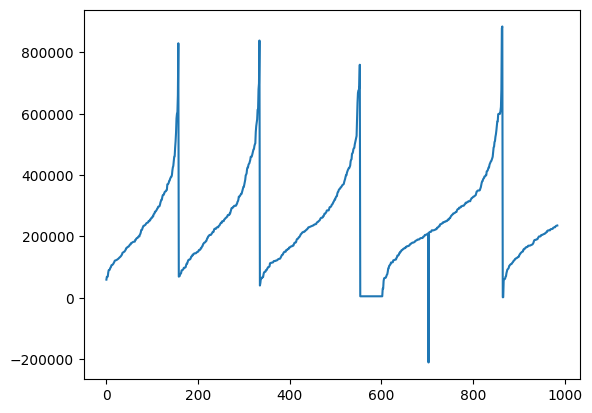

In [23]:
raw_df.price.plot()

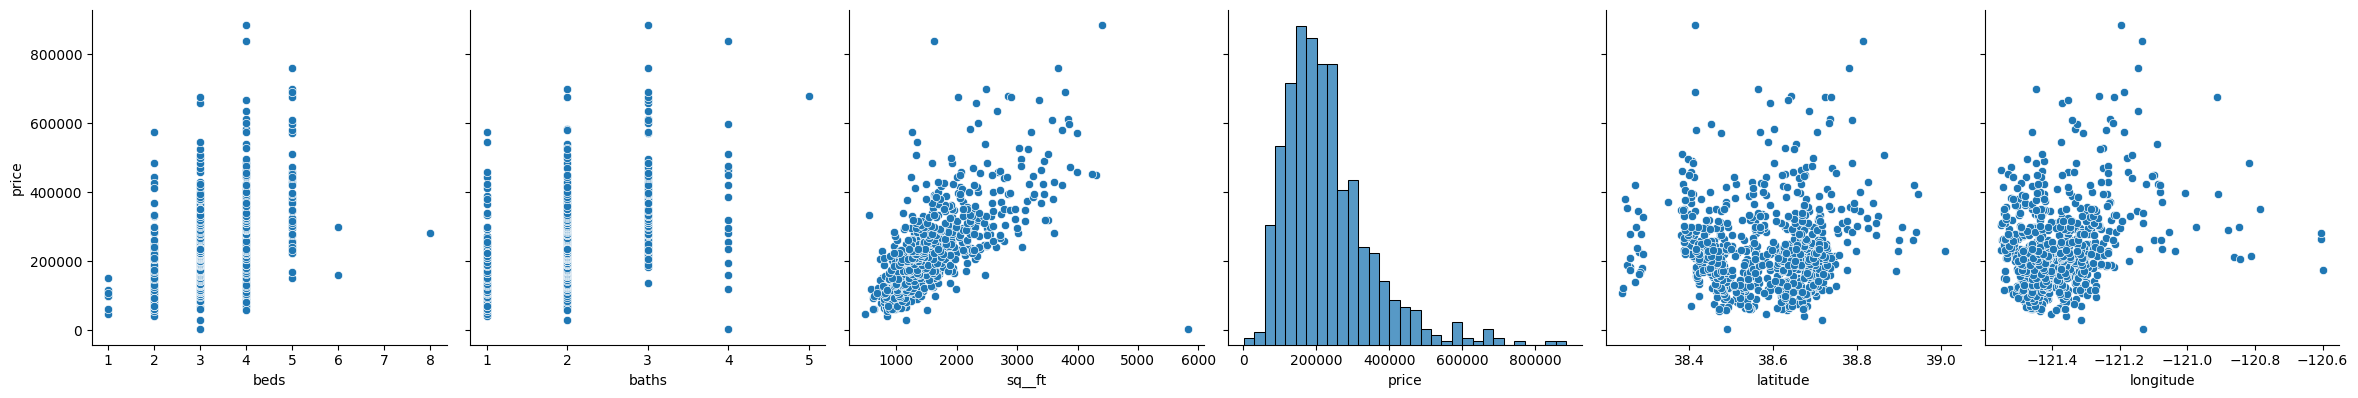

In [20]:
# FIRST EASIEST ATTEMPT: I FOCUS ON THE NUMERICAL COLUMNS
# I PLOT THEM TO SEE HOW THE TARGET VARIABLE (PRICE) CHANGES WITH EACH ONE OF
# THEM. I WILL USE A PAIR PLOT, WHICH IS A GOOD WAY TO SEE THE RELATIONSHIP
# BETWEEN TWO NUMERICAL VARIABLES.

# use seabiorn to create a pairplot of the numerical columns in the clean_df
# dataframe, with price as the target variable. This will help visualize the
# relationships between the features and the target variable.

target_col = 'price'

num_cols = no_area_df.select_dtypes(include='number')

sns.pairplot(clean_df, x_vars=num_cols, y_vars=target_col, height=4, aspect=1, kind='scatter')

In [25]:
# I see a point that is way out of the range of the other points. I want to know
# which property is that, so I will filter the dataframe to find it.

clean_df[clean_df['sq__ft'] >= 5000]

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
866,14151 INDIO DR,SLOUGHHOUSE,95683,CA,3,4,5822,Residential,Fri May 16 00:00:00 EDT 2008,2000,38.490447,-121.129337


In [28]:
clean_df[clean_df['price'] <= 10000]

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
866,14151 INDIO DR,SLOUGHHOUSE,95683,CA,3,4,5822,Residential,Fri May 16 00:00:00 EDT 2008,2000,38.490447,-121.129337


In [34]:
# I go back to EDA and remove that property from the clean_df dataframe.

clean_df = clean_df[clean_df['price'] > 10000]

In [35]:
clean_df.describe()

,beds,baths,sq__ft,price,latitude,longitude
count,812.000000,812.00000,812.000000,812.000000,812.000000,812.000000
mean,3.247537,1.95936,1586.683498,229751.267241,38.577038,-121.378840
std,0.849490,0.66594,647.477210,119704.946884,0.126393,0.119483
min,1.000000,1.00000,484.000000,30000.000000,38.241514,-121.550527
25%,3.000000,2.00000,1144.000000,148750.000000,38.473804,-121.451463
50%,3.000000,2.00000,1418.500000,207986.500000,38.591720,-121.405456
75%,4.000000,2.00000,1851.000000,285000.000000,38.675024,-121.326073
max,8.000000,5.00000,4400.000000,884790.000000,39.008159,-120.597599


### 4. Which variable would be the best predictor of Y in an SLR model? Why?

<Axes: >

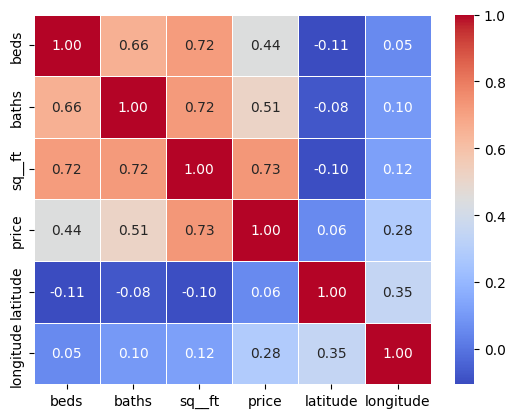

In [36]:
# FROM THE PLOTS I CAN SEE THAT AREA IS THE MOST IMPORTANT FEATURE, AND BEDS AND
# BATHS ARE NOT AS IMPORTANT. I CAN ALSO SEE THAT THERE ARE SOME OUTLIERS IN THE
# DATA, ESPECIALLY IN THE PRICE


# NEVERTHELESS, I WANT TO USE THE CORRELATION MATRIX AND A HEATMAP TO VISUALIZE THE
# CORRELATION BETWEEN THE NUMERICAL COLUMNS AND THE TARGET VARIABLE (PRICE).

corr_mtx = clean_df.corr(numeric_only=True)

sns.heatmap(corr_mtx, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)


In [37]:
# THE CORRELATION MATRIX LOOKS NICE AND THE HEATMAP IS COOL, BUT I DONT NEED ALL
# THAT INFO. I ONLY NEED TO SEE THE CORRELATION OF THE TARGET VARIABLE (PRICE)

target_corr = corr_mtx[target_col].sort_values(ascending=False)
display(target_corr)

,price
price,1.000000
sq__ft,0.728862
baths,0.513391
beds,0.443719
longitude,0.284564
latitude,0.057174


In [ ]:
# To the question "Which variable would be the best predictor of Y in an SLR model? Why?"

# My answer is: the area of the property in sq ft, because that one has the highest
# correlation with the target variable.

### 5. Using `scikit-learn` create a SLR and return the intercept and slope coefficients that minimize SSE.

#### SSE (Sum of Squared Errors)

SSE is just the total of all the squared prediction mistakes.

1. For each data point, figure out how far off your prediction was (actual minus predicted).
2. Square that number (to make negatives positive and punish big errors more).
3. Add them all up.

**Why it matters:** You were asked to find the slope and intercept that **minimize SSE**. That's literally what linear regression does — it searches for the line that makes this total as small as possible.

**Related terms:**
- **MSE** = SSE ÷ n (average of the squared errors)
- **RMSE** = √MSE (puts it back in original units)

So: **SSE → MSE → RMSE** is just the same number, adjusted differently for interpretation purposes.


-----

You may need to load in the scikit-learn API:

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
```



In [42]:
# Here is where I start myu data modelling ! :)

In [40]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [38]:
# Here I define my input and target variables
# scikit-learn needs the object with the input variables to have two dimensions,
# that is why I use clean_df[ {list of column names} ]

X = clean_df[['sq__ft']]

# y has to have only one dimension when we use scikit learn, and in general for
# linear regression: we only have one target
y = clean_df['price']


In [43]:
model.fit(X,y)

# I want the model coefficient (or slope for SLR) and intercept
display(f"The intercept is {model.intercept_.round(2)}")
display(f"The slope is {model.coef_[0].round(2)}")

'The intercept is 15943.75'

'The slope is 134.75'

### 5 [bonus]. Write a function that will take in two lists, `x` and `y`, and return the intercept and slope coefficients that minimize SSE.

`y` is the target variable, and `x` is the predictor variable.

**Don't use `scikit-learn` for this**. Instead, use `numpy` and `scipy`.

The slope and intercept of simple linear regression can be calculated by using certain summary statistics. In particular, we'll need to know:

- $\bar{x}$, the mean of `x`
- $\bar{y}$, the mean of `y`
- $s_{x}$, the standard deviation of `x`
- $s_{y}$, the standard deviation of `y`
- $r_{xy}$, the correlation of `x` and `y`

Given these summary statistics, the **coefficient on `X`** (or the slope) can be given by $\beta_{1} = r_{xy} * \frac{s_{y}}{s_{x}}$. The **intercept of the model** can be given by $\beta_{0} = \bar{y} - \beta_{1}\bar{x}$.

Your function should take in `x` and `y`, then use the above summary statistics to calculate the slope and intercept.

- **Test your function on price and the variable you determined was the best predictor in Problem 4.**
- **Report the slope and intercept.**

### 6. Interpret the intercept and the slope.

In your own words, write here what is the meaning of each one of those values
and how can they be helpful for you when predicting prices or interpreting the
predictions of your model.

In [44]:
# Again., what are the coefficients?
# I want the model coefficient (or slope for SLR) and intercept
display(f"The intercept is {model.intercept_.round(2)}")
display(f"The slope is {model.coef_[0].round(2)}")

'The intercept is 15943.75'

'The slope is 134.75'

*The intercept* is the price of a property with zero area, about 16 K acording to
this model. Such aproperty does not exist but this is telling me the lowest
possible price for a property in that area.

*The slope* is how much the price of a property wil change if the area increase
by 1 sq ft: 134 dolars (or the currency in which the price is)

### 7. Give an example of how this model could be used for prediction and how it could be used for inference.

**Be sure to make it clear which example is associated with prediction and which is associated with inference.**

In [45]:
# Prediction (here I use my model to estimate the price of a property)

# I want a house with 2000 sq ft. What should be my budget?

my_dream_house_sqft = 2000

# Remember X has to have two dimensions?
# so I use double brackets to create a 2D array with one row and one column

my_budget = model.predict([[my_dream_house_sqft]])

display(f"The budget for my dream house is ${my_budget[0].round(2)} ")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


'The budget for my dream house is $285446.17 '

In [ ]:
# Inference (here I want to know how much the price will change if I increase
# the area of my house by 100 sq ft, think of it as a sensitivity analysis or a
# scenario analysis)

# The slope will tell me how much the price will change for every 1 sq ft
# increase in area.




### 8: [Bonus] Using the model you came up with in Part 5, calculate and plot the residuals.

<Axes: title={'center': 'Residuals Histogram'}, xlabel='Residuals', ylabel='Frequency'>

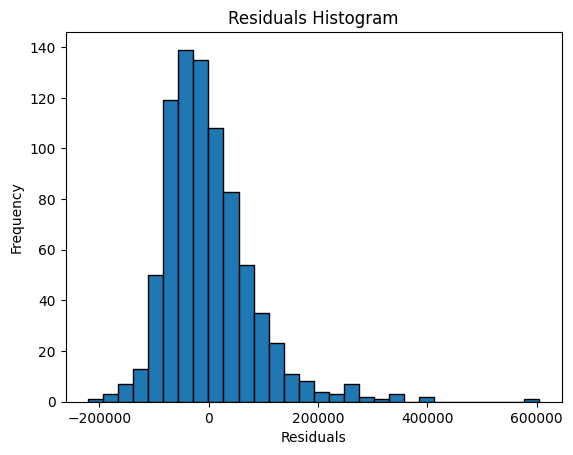

In [46]:
# The residuals ar the difference between the prices predicted by my model and the
# actual prices

# Real prices
y_real = y

# Predicted prices
y_pred = model.predict(X)

# Residuals
residuals = y_real - y_pred

residuals.plot(xlabel='Residuals', title='Residuals Histogram',kind='hist', bins=30, edgecolor='black',)


In [ ]:
# I would like to see the residuals per price and per area of the properties

residuals_df = pd.DataFrame({'Price': y_real, 'Area': X['sq__ft'], 'Residuals': residuals})

sns.pairplot(residuals_df, x_vars=['Price', 'Area'], y_vars=['Residuals'], height=4, aspect=1, kind='scatter')

---

## Reminder about categorical variables and dummy variables

It is important to be cautious with categorical variables, which represent distict groups or categories, when building a regression. If put in a regression "as-is," categorical variables represented as integers will be treated like *continuous* variables.

That is to say, instead of group "3" having a different effect on the estimation than group "1" it will estimate literally 3 times more than group 1.

For example, if occupation category "1" represents "analyst" and occupation category "3" represents "barista", and our target variable is salary, if we leave this as a column of integers then barista will always have `beta*3` the effect of analyst.

This will almost certainly force the beta coefficient to be something strange and incorrect. Instead, we can re-represent the categories as multiple "dummy coded" columns.



#### A Word of Caution When Creating Dummies

Let's touch on precautions we should take when dummy coding.

**If you convert a qualitative variable to dummy variables, you want to turn a variable with N categories into N-1 variables.**

> **Scenario 1:** Suppose we're working with the variable "sex" or "gender" with values "M" and "F".

You should include in your model only one variable for "sex = F" which takes on 1 if sex is female and 0 if sex is not female! Rather than saying "a one unit change in X," the coefficient associated with "sex = F" is interpreted as the average change in Y when sex = F relative to when sex = M.

| Female | Male |
|-------|------|
| 0 | 1 |
| 1 | 0 |
| 0 | 1 |
| 1 | 0 |
| 1 | 0 |
_As we can see a 1 in the female column indicates a 0 in the male column. And so, we have two columns stating the same information in different ways._

> Scenario 2: Suppose we're modeling revenue at a bar for each of the days of the week. We have a column with strings identifying which day of the week this observation occured in.

We might include six of the days as their own variables: "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday". **But not all 7 days.**  

|Monday | Tuesday | Wednesday | Thursday | Friday | Saturday |
|-------|---------|-----------|----------|--------|----------|
| 1     | 0       |0          |      0   |0       | 0        |
| 0     | 1       |0          |      0   |0       | 0        |
| 0     | 0       |1          |      0   |0       | 0        |
| 0     | 0       |0          |      1   |0       | 0        |
| 0     | 0       |0          |      0   |1       | 0        |
| 0     | 0       |0          |      0   |0       | 1        |
| 0     | 0       |0          |      0   |0       | 0        |

_As humans we can infer from the last row that if its is not Monday, Tuesday, Wednesday, Thursday, Friday or Saturday, it must be Sunday. Models work the same way._

The coefficient for Monday is then interpreted as the average change in revenue when "day = Monday" relative to "day = Sunday." The coefficient for Tuesday is interpreted as the average change in revenue when "day = Tuesday" relative to "day = Sunday" and so on.

The category you leave out, which the other columns are *relative to*, is often referred to as the **reference category**.

### 9. Use the `pd.get_dummies` function to convert the `type` column into dummy-coded variables.

In [47]:
# I know there are categorical variables that might impact the price
# I am going to focus on those to improve my model

# from the correlation:
display(target_corr)



,price
price,1.000000
sq__ft,0.728862
baths,0.513391
beds,0.443719
longitude,0.284564
latitude,0.057174


In [ ]:
# but I also have the columns that are text

text_df.columns

In [48]:
# I am going to focus on some of those columns
cat_cols = ['baths', 'beds', 'type']

cat_df = clean_df[cat_cols]
cat_df = pd.get_dummies(cat_df, columns=cat_cols, drop_first=True)
cat_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 812 entries, 0 to 984
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   baths_2            812 non-null    bool 
 1   baths_3            812 non-null    bool 
 2   baths_4            812 non-null    bool 
 3   baths_5            812 non-null    bool 
 4   beds_2             812 non-null    bool 
 5   beds_3             812 non-null    bool 
 6   beds_4             812 non-null    bool 
 7   beds_5             812 non-null    bool 
 8   beds_6             812 non-null    bool 
 9   beds_8             812 non-null    bool 
 10  type_Multi-Family  812 non-null    bool 
 11  type_Residential   812 non-null    bool 
dtypes: bool(12)
memory usage: 15.9 KB


### 10. Check the dummy columns you've created. Do they all make sense?

Use `.head()` on the new dataframe you've created. Depending on how you cleaned the data earlier in this notebook, there may be a dummy column that needs to be removed. Check that all the columns you've created make sense, and if any of the columns seem to be errors, drop them. If there don't appear to be any errors, then move on to the next step!

In [51]:
cat_df.beds_3.sum()

np.int64(391)

In [49]:
cat_df.describe()

,baths_2,baths_3,baths_4,baths_5,beds_2,beds_3,beds_4,beds_5,beds_6,beds_8,type_Multi-Family,type_Residential
count,812,812,812,812,812,812,812,812,812,812,812,812
unique,2,2,2,2,2,2,2,2,2,2,2,2
top,True,False,False,False,False,False,False,False,False,False,False,True
freq,507,702,796,811,687,421,577,763,810,811,799,758


In [ ]:
# Now my entire clean dataframe will be the combination of the numerical columns
# and the categorical columns

#clean_df = pd.concat([clean_df[['sq__ft']], cat_df], axis=1)
#clean_df.info()

In [52]:
# Now my entire clean dataframe will be the combination of the numerical columns
# and the categorical columns

multiv_X = pd.concat([clean_df[['sq__ft']], cat_df], axis=1)
multiv_X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 812 entries, 0 to 984
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   sq__ft             812 non-null    int64
 1   baths_2            812 non-null    bool 
 2   baths_3            812 non-null    bool 
 3   baths_4            812 non-null    bool 
 4   baths_5            812 non-null    bool 
 5   beds_2             812 non-null    bool 
 6   beds_3             812 non-null    bool 
 7   beds_4             812 non-null    bool 
 8   beds_5             812 non-null    bool 
 9   beds_6             812 non-null    bool 
 10  beds_8             812 non-null    bool 
 11  type_Multi-Family  812 non-null    bool 
 12  type_Residential   812 non-null    bool 
dtypes: bool(12), int64(1)
memory usage: 22.2 KB


# Multivariate Linear Regression Model (MLR)

### 11. Build what you think may be the best MLR model predicting `price`.

Choose at least three variables, and build a model that uses them to predict price. At least one of the variables you choose should be a dummy-coded variable. (This can be one we created before or a new one.)

You may need to load in the scikit-learn API:

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
```

In [53]:
# I have my new X
display(multiv_X.info())

# y is the same as before, the target variable (price)
display(y.info())

<class 'pandas.core.frame.DataFrame'>
Index: 812 entries, 0 to 984
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   sq__ft             812 non-null    int64
 1   baths_2            812 non-null    bool 
 2   baths_3            812 non-null    bool 
 3   baths_4            812 non-null    bool 
 4   baths_5            812 non-null    bool 
 5   beds_2             812 non-null    bool 
 6   beds_3             812 non-null    bool 
 7   beds_4             812 non-null    bool 
 8   beds_5             812 non-null    bool 
 9   beds_6             812 non-null    bool 
 10  beds_8             812 non-null    bool 
 11  type_Multi-Family  812 non-null    bool 
 12  type_Residential   812 non-null    bool 
dtypes: bool(12), int64(1)
memory usage: 22.2 KB


None

<class 'pandas.core.series.Series'>
Index: 812 entries, 0 to 984
Series name: price
Non-Null Count  Dtype
--------------  -----
812 non-null    int64
dtypes: int64(1)
memory usage: 12.7 KB


None

In [54]:
model2 = LinearRegression()

model2.fit(multiv_X,y)

# I want the model coefficient (or slope for SLR) and intercept
display(f"The intercept is {model2.intercept_.round(2)}")
display(f"The slope is {model2.coef_[0].round(2)}")

'The intercept is -14439.15'

'The slope is 156.52'

### 12. Plot the true price vs the predicted price to evaluate your MLR visually.

You can use matplotlib or seaborn, the choice is yours !

<Axes: title={'center': 'Residuals Histogram'}, xlabel='Residuals', ylabel='Frequency'>

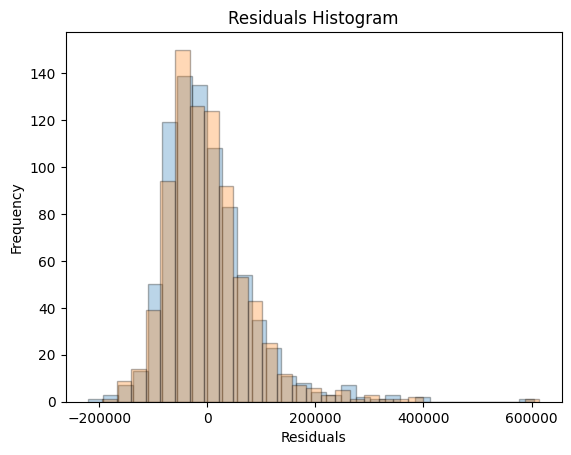

In [55]:
# The residuals ar the difference between the prices predicted by my model and the
# actual prices

# Real prices
y_real = y

# Predicted prices
y_pred = model2.predict(multiv_X)

# Residuals
residuals2 = y_real - y_pred

# My first model SLR
residuals.plot(xlabel='Residuals', title='Residuals Histogram',kind='hist', bins=30, edgecolor='black',alpha=0.3, label='Model 1' )

# My new model MLR
residuals2.plot(xlabel='Residuals', title='Residuals Histogram',kind='hist', bins=30, edgecolor='black',alpha=0.3, label='Model 2')


### 13. List the five assumptions for an MLR model.

Indicate which ones are the same as the assumptions for an SLR model.

In [ ]:
# convert this cell to markdown to provide your answer

### 14. Pick at least two assumptions and explain whether or not you believe them to be met for your model, and explain why.

### 15. [Bonus - optional] Generate a table showing the point estimates, standard errors, t-scores, p-values, and 95% confidence intervals for the model you built.

**Write a few sentences interpreting some of the output.**

> **Hint:** scikit-learn does not have this functionality built in, but statsmodels does in the `summary` method.  To fit the statsmodels model use something like the following.  There is one big caveat here, however!  `statsmodels.OLS` does _not_ add an intercept to your model, so you will need to do this explicitly by adding a column filled with the number 1 to your X matrix

```python
import statsmodels.api as sm

# The Default here is Linear Regression (ordinary least squares regression OLS)
model = sm.OLS(y,X).fit()
```

### 16. Metrics, metrics, everywhere...

Calculate and interpret at least three regression metrics. How well does your model perform?

## Metric Comparison Table

| Metric | What It Tells You | Punishes Big Mistakes? | Adjusts for Extra Inputs? | Examples of When to Use It |
|---|---|---|---|---|
| **R²** | What percent of the output's variation did the model explain? (0% to 100%) | Indirectly | ❌ No | • Pitching model quality in a presentation: "My model explains 73% of the price variation."<br>• Comparing two models on the same dataset.<br>• Quick sanity check: if R² is near zero, your inputs aren't helping. |
| **Adjusted R²** | Like R², but penalizes you for throwing in too many inputs | Indirectly | ✅ Yes | • You add/remove variables and want to know if performance truly improved.<br>• Deciding whether a new feature is worth keeping in production.<br>• Anytime you're comparing models with different numbers of predictors. |
| **MSE** | Average squared error. Lower is better. | ✅ Strongly (squared!) | ❌ No | • The loss function that regression algorithms optimize internally.<br>• Math-heavy contexts (calculus, derivation).<br>• Rarely reported to stakeholders — too abstract. |
| **RMSE** | On average, how far off are predictions (in original units)? | ✅ Strongly | ❌ No | • "Predictions are off by ~$45,000 on average."<br>• Reporting to non-technical audiences who want dollar amounts.<br>• When large outliers matter and you want to catch them. |
| **MAE** | On average, how far off are predictions (in original units)? | ❌ Mildly (linear) | ❌ No | • When outliers are noisy measurements you don't want to overweight.<br>• Plain-language explanations: "Typical error is about $40,000."<br>• When you want a robust, easy-to-grasp error measure. |

---

## Which Metrics to Report?

**Quick analogy:** If you're reporting to your professor, think of it like grading on multiple axes:
- **R²** answers: "How much of the puzzle did you solve?"
- **RMSE/MAE** answer: "By how many points, on average, were your answers wrong?"
- **Adjusted R²** answers: "Did you actually improve, or just throw more pages at the problem?"

### 16. [Bonus - Optional] Regression Metrics

Implement a function called `r2_adj()` that will calculate $R^2_{adj}$ for a model.

### 18. Model Iteration

Adjust your model by adding or removing a variable. Then calculate the same regression metrics as you used in question 17. Has your model performance increased or decreased?

### 19. Bias vs. Variance

At this point, do you think your model is high bias, high variance or in the
sweet spot?

Hint: cross validation, test ... !